# Stage 4 — Results analysis

Loads the feature table, runs the probe protocol and the full statistical suite (`sec:analysis_method`) for one experiment (E1/E2/E3), and produces the thesis figures:

- per-layer folded AUROC profiles with the permutation-scan threshold,
- test AUROC with bootstrap CI (base vs full probe),
- ΔAUROC paired bootstrap (the contribution claim),
- β-sensitivity curve (E1 only, from cached score tensors),
- per-category descriptive table.

Confirmatory family = exactly {discrimination, contribution}, Bonferroni at family α = 0.05 (decisions read the 97.5% CIs). Everything else is exploratory/descriptive. Every figure is saved to `results/<experiment>/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "configs").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from energy_llm.config import load_config

EXPERIMENT = "e2"  # e1 | e2 | e3
cfg = load_config(REPO_ROOT / f"configs/{EXPERIMENT}.yaml")
cfg.output_dir = str(REPO_ROOT / cfg.output_dir)
FIG_DIR = cfg.figures_dir
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
GROUP_LABELS = {"delta_energy": r"$\Delta E$", "delta_norm_entropy": r"$\Delta\bar{H}$",
                "mean_js": r"$\overline{\mathrm{JS}}$",
                "mean_hellinger_sq": r"$\overline{H^2_{\mathrm{Hel}}}$"}

import json
cal = json.loads((REPO_ROOT / f"results/{EXPERIMENT}/calibration/calibration.json").read_text())
cfg.calibration.beta_star = cal["beta_star"]
print(f"experiment: {cfg.name}   beta* = {cfg.calibration.beta_star}")

experiment: e2_llama_truthfulqa   beta* = 5.058341935910842


## Load features and labels

In [2]:
from energy_llm.features import infer_n_layers, phi_matrix, baseline_matrix, PHI_GROUPS
from energy_llm.labeling import load_labels

# Leer features ya calculados en HPC
df = pd.read_csv(REPO_ROOT / f"results/{EXPERIMENT}/features/features.csv")
labels = json.loads((REPO_ROOT / f"results/{EXPERIMENT}/labels.json").read_text())
df["is_hallucination"] = df["sample_id"].map(labels)
df = df[df["is_hallucination"].notna()].reset_index(drop=True)

n_layers = infer_n_layers(df)
y = df["is_hallucination"].to_numpy(dtype=int)
X_phi = phi_matrix(df, n_layers)
X_base = baseline_matrix(df)

print(f"labelled samples: {len(df)}   L = {n_layers}   phi dim = {X_phi.shape[1]}")
print(f"hallucination rate: {y.mean():.3f}")

labelled samples: 817   L = 28   phi dim = 112
hallucination rate: 0.528


## Locked split and probes

70/15/15 stratified at seed 42; calibration ids forced into train; test split hashed and locked. Base probe = baselines only; full probe = baselines + φ, identical protocol.

In [3]:
split_path = REPO_ROOT / f"results/{EXPERIMENT}/split.json"
print(f"split.json exists: {split_path.exists()}")
print(f"calibration.json exists: {(REPO_ROOT / f'results/{EXPERIMENT}/calibration/calibration.json').exists()}")

split.json exists: True
calibration.json exists: True


In [4]:
from energy_llm.io_artifacts import load_json
from energy_llm.probe import make_locked_splits, run_base_and_full_probes

cal_path = cfg.calibration_dir / "calibration.json"
cal_ids = load_json(cal_path)["calibration_sample_ids"] if cal_path.exists() else []

splits = make_locked_splits(
    df["sample_id"].tolist(), y, cfg.out / "split.json",
    seed=cfg.seed, ratios=tuple(cfg.probe.split), force_train_ids=cal_ids,
)
idx = splits.index_of(df["sample_id"].tolist())
print({k: len(v) for k, v in idx.items()}, "test hash:", splits.test_hash[:12], "…")

probes = run_base_and_full_probes(
    X_base, X_phi, y, idx, c_grid=cfg.probe.c_grid,
    inner_cv_folds=cfg.probe.inner_cv_folds,
    outer_cv_folds=cfg.probe.outer_cv_folds, seed=cfg.seed,
)
for kind in ("base", "full"):
    p = probes[kind]
    print(f"{kind:4s}  C={p['best_c']:<5}  test AUROC={p['test_auroc']:.4f}  "
          f"outer 5-fold CV {p['outer_cv_auroc_mean']:.4f} ± {p['outer_cv_auroc_std']:.4f} (descriptive)")

{'train': 571, 'val': 123, 'test': 123} test hash: a7d4091769ef …
base  C=10.0   test AUROC=0.5546  outer 5-fold CV 0.6352 ± 0.0451 (descriptive)
full  C=10.0   test AUROC=0.6870  outer 5-fold CV 0.7147 ± 0.0370 (descriptive)


In [5]:
print(probes["full"].keys())

dict_keys(['best_c', 'inner_cv_auroc_by_c', 'outer_cv_aurocs', 'outer_cv_auroc_mean', 'outer_cv_auroc_std', 'test_auroc', 'test_scores', 'y_test', 'pipeline'])


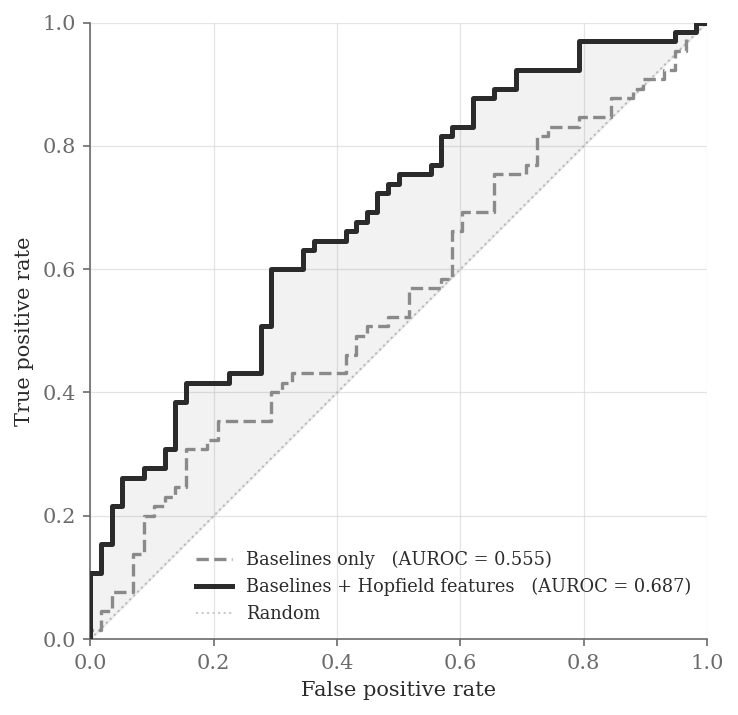

Saved roc_test_split.png


In [6]:
from sklearn.metrics import roc_curve

# estilo del capítulo (mismo de notebooks 01 / calibración)
PALETTE = {"factual": "#3C6E8F", "halluc": "#B5544E", "ink": "#2B2B2B",
           "muted": "#6B6B6B", "grid": "#D6D9DC", "panel": "#F4F6F8"}
plt.rcParams.update({
    "font.family": "serif", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": PALETTE["ink"], "axes.labelcolor": PALETTE["ink"],
    "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "figure.dpi": 150,
})

# esquema monocromo para comparación de método (no colisiona con clase/modelo)
SPEC = {
    "base": dict(color="#8A8A8A",      ls="--", lw=1.6,
                 label="Baselines only"),
    "full": dict(color=PALETTE["ink"], ls="-",  lw=2.4,
                 label="Baselines + Hopfield features"),
}

fig, ax = plt.subplots(figsize=(5.0, 5.0))

for kind in ("base", "full"):
    p = probes[kind]
    fpr, tpr, _ = roc_curve(p["y_test"], p["test_scores"])
    sp = SPEC[kind]
    ax.plot(fpr, tpr, color=sp["color"], ls=sp["ls"], lw=sp["lw"], zorder=3,
            label=f"{sp['label']}   (AUROC = {p['test_auroc']:.3f})")
    if kind == "full":
        ax.fill_between(fpr, tpr, fpr, where=(tpr >= fpr),
                        color=PALETTE["ink"], alpha=0.06, zorder=2)

# chance line (tenue, punteada)
ax.plot([0, 1], [0, 1], color="#C9C9C9", lw=1.0, ls=":",
        zorder=1, label="Random")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_aspect("equal")
ax.grid(color=PALETTE["grid"], lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")

fig.tight_layout()
fig.savefig(FIG_DIR / "roc_test_split.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved roc_test_split.png")

## Confirmatory claims: discrimination and contribution

In [7]:
from energy_llm.stats import bootstrap_auroc_ci, paired_bootstrap_delta_auroc

y_test = probes["full"]["y_test"]
discrimination = bootstrap_auroc_ci(
    y_test, probes["full"]["test_scores"],
    n_bootstrap=cfg.stats.n_bootstrap, seed=cfg.seed)
contribution = paired_bootstrap_delta_auroc(
    y_test, probes["full"]["test_scores"], probes["base"]["test_scores"],
    n_bootstrap=cfg.stats.n_bootstrap, seed=cfg.seed)

print(f"DISCRIMINATION  AUROC = {discrimination['auroc']:.4f}")
print(f"  95%   CI {discrimination['ci_0.950']}   -> claim: {discrimination['discriminates_95']}")
print(f"  97.5% CI {discrimination['ci_0.975']}   -> Bonferroni: {discrimination['discriminates_bonferroni']}")
print(f"CONTRIBUTION    dAUROC = {contribution['delta_auroc']:.4f}  "
      f"(full {contribution['auroc_full']:.4f} vs base {contribution['auroc_base']:.4f})")
print(f"  95%   CI {contribution['ci_0.950']}   -> claim: {contribution['contributes_95']}")
print(f"  97.5% CI {contribution['ci_0.975']}   -> Bonferroni: {contribution['contributes_bonferroni']}")

DISCRIMINATION  AUROC = 0.6870
  95%   CI [0.5905671695208102, 0.7787080404956137]   -> claim: True
  97.5% CI [0.5751275745641943, 0.7917351309681396]   -> Bonferroni: True
CONTRIBUTION    dAUROC = 0.1324  (full 0.6870 vs base 0.5546)
  95%   CI [0.013754888428801465, 0.2506664140122735]   -> claim: True
  97.5% CI [-0.002916445974576302, 0.26472615858078963]   -> Bonferroni: False


In [8]:
print("discrimination:", discrimination.keys())
print("contribution  :", contribution.keys())

discrimination: dict_keys(['auroc', 'n_bootstrap', 'n_test', 'ci_0.950', 'ci_0.975', 'discriminates_95', 'discriminates_bonferroni'])
contribution  : dict_keys(['delta_auroc', 'auroc_full', 'auroc_base', 'n_bootstrap', 'n_test', 'ci_0.950', 'ci_0.975', 'contributes_95', 'contributes_bonferroni'])


In [9]:
import numpy as np
from sklearn.metrics import roc_auc_score

PALETTE = {"factual": "#3C6E8F", "halluc": "#B5544E", "ink": "#2B2B2B",
           "muted": "#6B6B6B", "grid": "#D6D9DC", "panel": "#F4F6F8"}
GRAY = "#8A8A8A"
DISPLAY = {"e1": "Experiment 1 — Qwen2.5-3B, TruthfulQA",
           "e2": "Experiment 2 — LLaMA-3.2-3B, TruthfulQA",
           "e3": "Experiment 3 — Qwen2.5-3B, TriviaQA"}

y_test = probes["full"]["y_test"]
s_full = probes["full"]["test_scores"]
s_base = probes["base"]["test_scores"]
base_ci = bootstrap_auroc_ci(y_test, s_base,
                             n_bootstrap=cfg.stats.n_bootstrap, seed=cfg.seed)
# paired bootstrap distribution — public API, same B and seed, single-class redraw
def paired_delta_draws(y, sf, sb, B, seed):
    rng, n, out = np.random.default_rng(seed), len(y), []
    while len(out) < B:
        idx = rng.integers(0, n, n)
        yi = y[idx]
        if yi.min() == yi.max():               # AUROC undefined -> redraw
            continue
        out.append(roc_auc_score(yi, sf[idx]) - roc_auc_score(yi, sb[idx]))
    return np.asarray(out)

draws = paired_delta_draws(y_test, s_full, s_base, cfg.stats.n_bootstrap, cfg.seed)
emp = np.percentile(draws, [1.25, 98.75])      # ~97.5% two-sided (Bonferroni, 2 tests)
print(f"recomputed 97.5% CI [{emp[0]:.3f}, {emp[1]:.3f}]  vs reported "
      f"{tuple(round(x, 3) for x in contribution['ci_0.975'])}")


recomputed 97.5% CI [-0.003, 0.265]  vs reported (-0.003, 0.265)


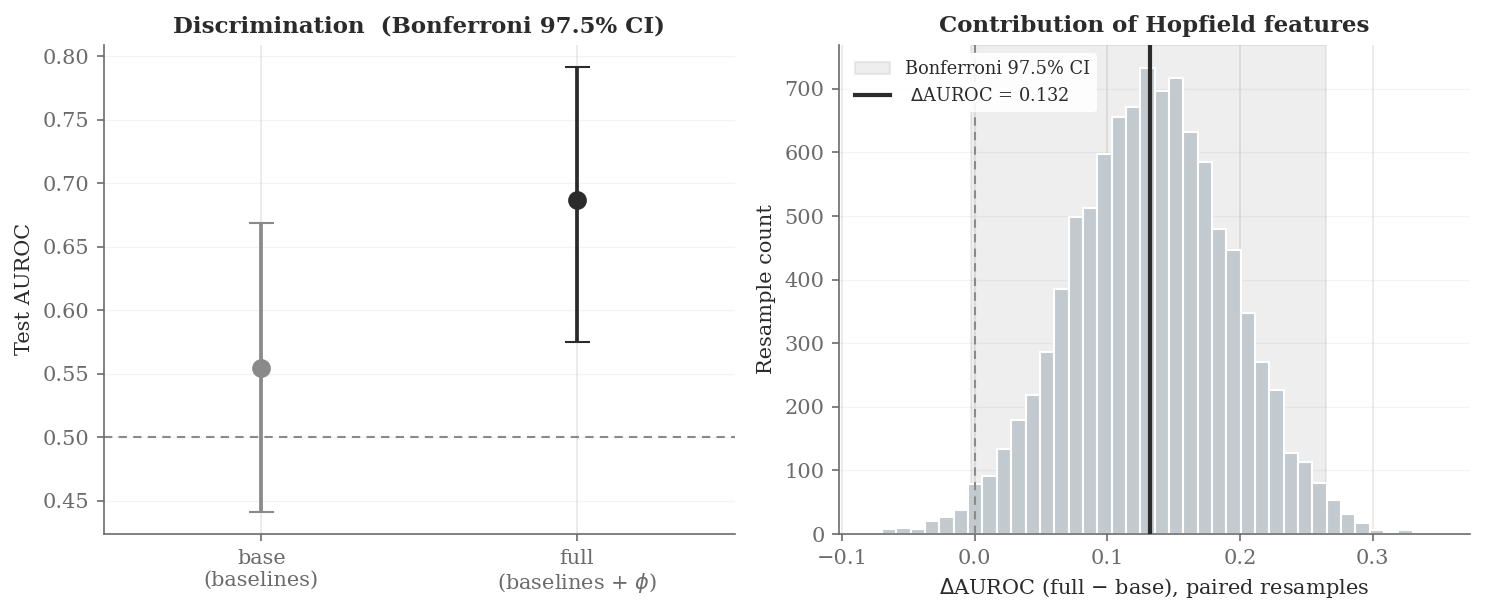

Saved confirmatory_results.png


In [10]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# ── panel 1: discrimination (base vs full AUROC, Bonferroni 97.5% CI) ──
ax = axes[0]
pts = [("base\n(baselines)",            base_ci,        GRAY),
       ("full\n(baselines + $\\phi$)",  discrimination, PALETTE["ink"])]
for i, (lab, ci, col) in enumerate(pts):
    lo95, hi95 = ci["ci_0.950"]
    lo,   hi   = ci["ci_0.975"]
    ax.plot([i, i], [lo95, hi95], color=col, lw=1.0, alpha=0.45, zorder=2)   # 95% inner
    ax.errorbar(i, ci["auroc"], yerr=[[ci["auroc"] - lo], [hi - ci["auroc"]]],
                fmt="o", capsize=6, markersize=8, color=col, lw=1.8, zorder=3)
ax.axhline(0.5, ls=(0, (4, 3)), color=GRAY, lw=1.0)
ax.set_xlim(-0.5, 1.5); ax.set_xticks([0, 1]); ax.set_xticklabels([p[0] for p in pts])
ax.set_ylabel("Test AUROC")
ax.set_title("Discrimination  (Bonferroni 97.5% CI)")
ax.grid(axis="y", color=PALETTE["grid"], lw=0.6); ax.set_axisbelow(True)

# ── panel 2: contribution (paired ΔAUROC) ──
ax = axes[1]
ax.hist(draws, bins=40, color="#C2CACF", edgecolor="white", zorder=2)
lo, hi = contribution["ci_0.975"]
ax.axvspan(lo, hi, color=PALETTE["ink"], alpha=0.08, zorder=1,
           label="Bonferroni 97.5% CI")
ax.axvline(0, ls=(0, (4, 3)), color=GRAY, lw=1.0, zorder=3)
ax.axvline(contribution["delta_auroc"], color=PALETTE["ink"], lw=2.0, zorder=4,
           label=f" $\\Delta$AUROC = {contribution['delta_auroc']:.3f}")
ax.set_xlabel("$\\Delta$AUROC (full $-$ base), paired resamples")
ax.set_ylabel("Resample count")
ax.set_title("Contribution of Hopfield features")
ax.legend(loc="upper left", fontsize=8.5,
          frameon=True, framealpha=0.9, edgecolor="none")
ax.grid(axis="y", color=PALETTE["grid"], lw=0.6); ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(FIG_DIR / "confirmatory_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved confirmatory_results.png")

## Depth-axis localisation (exploratory)

Folded per-layer AUROC `max(AUROC, 1−AUROC)` for each of the 4 φ features, against the permutation null of the scan maximum over ALL layer-feature pairs (B_perm = 1000, 95th percentile).

In [11]:
from energy_llm.stats import permutation_scan_threshold

scan = permutation_scan_threshold(X_phi, y, n_permutation=cfg.stats.n_permutation,
                                  seed=cfg.seed)
observed = scan["observed_folded_auroc"].reshape(len(PHI_GROUPS), n_layers)



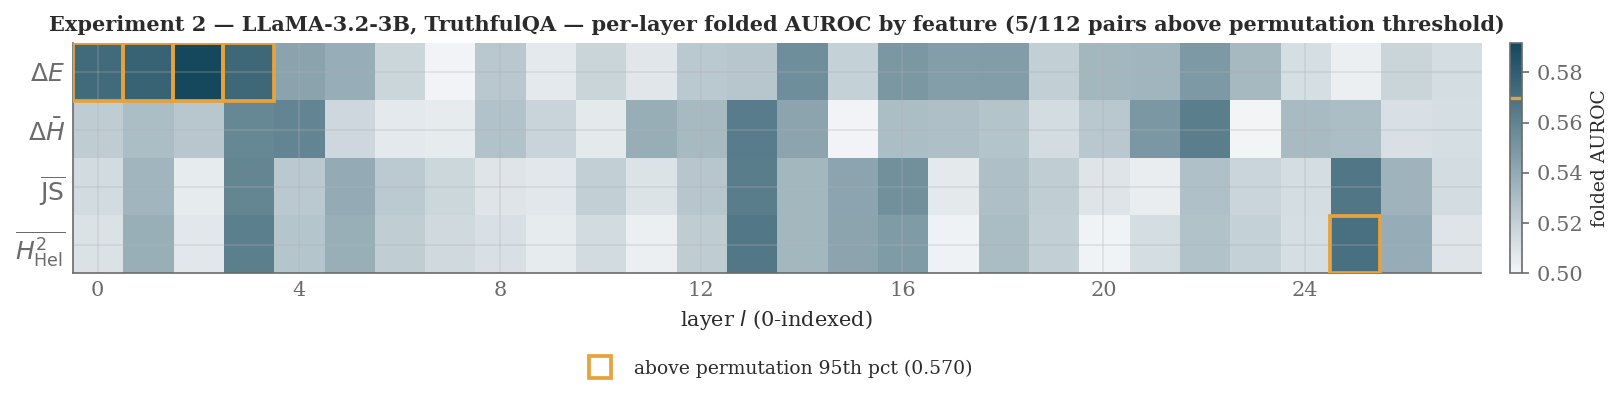

scan_threshold = 0.5699   n_significant = 5


In [12]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

observed = scan["observed_folded_auroc"].reshape(len(PHI_GROUPS), n_layers)
thr      = scan["scan_threshold"]

# magnitude colormap (distinct from the categorical class/model colors)
CMAP_LOC = LinearSegmentedColormap.from_list("loc", ["#F4F6F8", "#15485C"])

fig, ax = plt.subplots(figsize=(11, 3.0))
im = ax.imshow(observed, aspect="auto", cmap=CMAP_LOC,
               vmin=0.5, vmax=observed.max())

# outline (feature, layer) pairs above the permutation threshold
sig = observed > thr
for g in range(observed.shape[0]):
    for l in range(observed.shape[1]):
        if sig[g, l]:
            ax.add_patch(Rectangle((l - 0.5, g - 0.5), 1, 1, fill=False,
                                   edgecolor="#E6A23C", lw=1.8, zorder=3))

ax.set_yticks(range(len(PHI_GROUPS)))
ax.set_yticklabels([GROUP_LABELS[g] for g in PHI_GROUPS], fontsize=12)
ax.set_xticks(range(0, n_layers, 4))
ax.set_xlabel("layer $l$ (0-indexed)")
ax.set_title(f"{DISPLAY[EXPERIMENT]} — per-layer folded AUROC by feature "
             f"({scan['n_significant']}/{4 * n_layers} pairs above permutation threshold)",
             fontsize=10)
ax.tick_params(length=0)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("folded AUROC", fontsize=9)
cbar.ax.axhline(thr, color="#E6A23C", lw=1.6)          # threshold on the colorbar

proxy = [Line2D([0], [0], marker="s", ls="none", markersize=11,
                markerfacecolor="none", markeredgecolor="#E6A23C",
                markeredgewidth=1.8,
                label=f"above permutation 95th pct ({thr:.3f})")]
ax.legend(handles=proxy, loc="upper center", bbox_to_anchor=(0.5, -0.30),
          frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIG_DIR / "per_layer_folded_auroc.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"scan_threshold = {thr:.4f}   n_significant = {scan['n_significant']}")

## β sensitivity from precomputed CSV (descriptive)

Two-panel figure from `beta_sensitivity.csv` (generated by
`scripts/run_beta_sensitivity.py`): left = mean Δ*H̄* per sample vs β split
by hallucination class; right = full-probe AUROC vs β with β★ marked.
Run `sbatch hpc/beta_sensitivity.sbatch configs/e1.yaml` to produce the CSV.

In [13]:
print(cfg.out)
beta_sensitivity_csv = cfg.out / "beta_sensitivity.csv"
print(beta_sensitivity_csv)
print(beta_sensitivity_csv.exists())

/home/brandon/energy_llm/results/e2
/home/brandon/energy_llm/results/e2/beta_sensitivity.csv
False


In [14]:
if beta_sensitivity_csv.exists():
    bs = pd.read_csv(beta_sensitivity_csv)
    agg = (bs.dropna(subset=["is_hallucination"])
             .groupby(["beta", "is_hallucination"])["mean_delta_hbar"]
             .mean().reset_index())
    auroc_curve = (bs.drop_duplicates("beta")[["beta", "probe_auroc"]]
                     .sort_values("beta"))
    bstar = cfg.calibration.beta_star
    CLASS_STYLE = {0: ("Factual", PALETTE["factual"]),
                   1: ("Hallucination", PALETTE["halluc"])}

    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12, 4.5))

    # izquierda: ΔH̄ por clase vs β
    for label, grp in agg.groupby("is_hallucination"):
        name, color = CLASS_STYLE[int(label)]
        ax_l.plot(grp["beta"], grp["mean_delta_hbar"], marker="o", ms=4,
                  color=color, label=name)
    ax_l.axvline(bstar, color=PALETTE["muted"], ls="--", lw=1.2,
                 label=rf"$\beta^\star$ = {bstar:.2f}")
    ax_l.axhline(0, color=PALETTE["grid"], lw=0.8)
    ax_l.set_xscale("log"); ax_l.set_xlabel(r"$\beta$")
    ax_l.set_ylabel(r"mean $\Delta\bar{H}$ (averaged over layers)")
    ax_l.set_title("Entropy shift by class vs. $\\beta$")
    ax_l.legend(fontsize=9, frameon=False)
    ax_l.grid(color=PALETTE["grid"], lw=0.6, alpha=0.7); ax_l.set_axisbelow(True)

    # derecha: AUROC vs β (robustez)
    ax_r.plot(auroc_curve["beta"], auroc_curve["probe_auroc"],
              marker="o", ms=5, color=PALETTE["ink"], lw=1.8)
    ax_r.axvline(bstar, color=PALETTE["muted"], ls="--", lw=1.2,
                 label=rf"$\beta^\star$ = {bstar:.2f} (calibrated, not tuned)")
    ax_r.axhline(0.5, color=PALETTE["grid"], ls=":", lw=1.0)
    ax_r.set_xscale("log"); ax_r.set_xlabel(r"$\beta$")
    ax_r.set_ylabel("full-probe test AUROC")
    ax_r.set_title("Probe AUROC vs. $\\beta$  (descriptive)")
    ax_r.set_ylim(0.48, 0.70)
    ax_r.legend(fontsize=9, frameon=False)
    ax_r.grid(color=PALETTE["grid"], lw=0.6, alpha=0.7); ax_r.set_axisbelow(True)

    fig.suptitle(DISPLAY[EXPERIMENT], y=1.02, fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "beta_sensitivity.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(f"beta_sensitivity.csv not found at {beta_sensitivity_csv}")

beta_sensitivity.csv not found at /home/brandon/energy_llm/results/e2/beta_sensitivity.csv


## Single-feature unsupervised AUROC (best layer per feature, no fitting)

In [15]:
rows = []
for g, group in enumerate(PHI_GROUPS):
    best_l = int(np.argmax(observed[g]))
    rows.append({"feature": group, "best_layer": best_l,
                 "folded_auroc": observed[g, best_l],
                 "above_scan_threshold": observed[g, best_l] > scan["scan_threshold"]})
single_feature_table = pd.DataFrame(rows)
single_feature_table


,feature,best_layer,folded_auroc,above_scan_threshold
0,delta_energy,2,0.591437,True
1,delta_norm_entropy,13,0.563901,False
2,mean_js,25,0.566528,False
3,mean_hellinger_sq,25,0.570243,True


In [16]:
disp = single_feature_table.copy()
disp = disp.rename(columns={"best_layer": "Best layer",
                            "folded_auroc": "Folded AUROC",
                            "above_scan_threshold": "Significant"})
disp["Folded AUROC"] = disp["Folded AUROC"].round(3)
disp = disp.sort_values("Folded AUROC", ascending=False).reset_index(drop=True)
disp

,feature,Best layer,Folded AUROC,Significant
0,delta_energy,2,0.591,True
1,mean_hellinger_sq,25,0.570,True
2,mean_js,25,0.567,False
3,delta_norm_entropy,13,0.564,False


## Save the summary

In [17]:
from energy_llm.io_artifacts import save_json_atomic

summary = {
    "experiment": cfg.name,
    "beta_star": cfg.calibration.beta_star,
    "n_labelled": int(len(df)),
    "hallucination_rate": float(y.mean()),
    "split_sizes": {k: int(len(v)) for k, v in idx.items()},
    "test_split_hash": splits.test_hash,
    "base": {"test_auroc": probes["base"]["test_auroc"], "best_c": probes["base"]["best_c"],
             "ci_95": base_ci["ci_0.950"]},
    "full": {"test_auroc": probes["full"]["test_auroc"], "best_c": probes["full"]["best_c"],
             "ci_95": discrimination["ci_0.950"], "ci_97_5": discrimination["ci_0.975"]},
    "delta_auroc": {"point": contribution["delta_auroc"],
                    "ci_95": contribution["ci_0.950"], "ci_97_5": contribution["ci_0.975"]},
    "confirmatory_bonferroni": {
        "discrimination": bool(discrimination["discriminates_bonferroni"]),
        "contribution": bool(contribution["contributes_bonferroni"]),
    },
    "scan_threshold": scan["scan_threshold"],
    "n_layer_feature_pairs_significant": int(scan["n_significant"]),
    "beta_sensitivity": [],
}
save_json_atomic(cfg.out / "analysis_summary.json", summary)
print(f"written: {cfg.out / 'analysis_summary.json'}")
print(f"figures: {sorted(p.name for p in FIG_DIR.iterdir())}")

written: /home/brandon/energy_llm/results/e2/analysis_summary.json
figures: ['calibration_curve.png', 'confirmatory_results.png', 'e2_per_layer_folded_auroc.png', 'e2_test_auroc_and_delta.png', 'judge_human_agreement.png', 'label_distribution.png', 'label_distribution_all.png', 'per_category_auroc.csv', 'per_layer_folded_auroc.png', 'roc_test_split.png']
